# Component 02: WAV2VEC2 bird classification
J26-IT-359. This notebook has no training results. Use a VS Code Jupyter kernel with PyTorch installed. CUDA, Apple MPS, and CPU are supported.
Checkpoint: `facebook/wav2vec2-base`. A new 10-class classification head replaces the pretrained task head. Head initialization warnings are expected. Training and test evaluation are separately opt-in.


## 1. Dependencies and runtime
Run this cell with the same Python interpreter selected as the VS Code notebook kernel. It installs PyTorch if missing, then the remaining dependencies. Restart the kernel after installation if Python requests it, and rerun from the top. A GPU is strongly recommended for full training.


In [2]:
import importlib.metadata, subprocess, sys
print('Notebook Python:', sys.executable)
try:
    installed_torch = importlib.metadata.version('torch')
except importlib.metadata.PackageNotFoundError:
    installed_torch = None
if installed_torch is None or tuple(int(v) for v in installed_torch.split('+')[0].split('.')[:2]) < (2, 6):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'torch>=2.6'])
subprocess.check_call([sys.executable, '-m', 'pip', 'install',
    'transformers==4.57.1', 'optuna==4.5.0', 'scikit-learn==1.7.2',
    'librosa==0.11.0', 'soundfile==0.13.1', 'pandas>=2.2,<3',
    'matplotlib>=3.8,<4', 'tqdm>=4.66,<5', 'safetensors>=0.4.3', 'huggingface-hub>=0.34,<1'])
print('Dependencies installed for', sys.executable)


Notebook Python: /usr/local/bin/python3
Dependencies installed for /usr/local/bin/python3



[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [3]:
import os
os.environ['CUBLAS_WORKSPACE_CONFIG']=':4096:8'
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK','1')
from pathlib import Path
from datetime import datetime,timezone
import json,math,random,hashlib,zipfile,shutil,gc,platform,importlib.metadata,tempfile
from contextlib import nullcontext
import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset,DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score,accuracy_score,classification_report,confusion_matrix,ConfusionMatrixDisplay
import optuna
from transformers import AutoConfig,AutoFeatureExtractor,Wav2Vec2ForSequenceClassification,get_cosine_schedule_with_warmup
from huggingface_hub import HfApi
from safetensors.torch import load_file
from IPython.display import display
from tqdm.auto import tqdm
assert tuple(int(v) for v in torch.__version__.split('+')[0].split('.')[:2]) >= (2,6), 'Install torch >=2.6 in the selected VS Code kernel and restart it'
SEED=42
def seed_everything(seed):
 random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
 if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
 torch.backends.cudnn.benchmark=False;torch.backends.cudnn.deterministic=True
 torch.use_deterministic_algorithms(True,warn_only=True)
seed_everything(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
USE_AMP=DEVICE.type=='cuda'
AMP_DTYPE=torch.bfloat16 if USE_AMP and torch.cuda.is_bf16_supported() else torch.float16
DEVICE_NAME=torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else ('Apple MPS' if DEVICE.type=='mps' else 'CPU')
print('Device:',DEVICE_NAME,'mixed precision:',AMP_DTYPE if USE_AMP else 'disabled (float32)')
if DEVICE.type=='cpu': print('CPU training on 29,402 clips will be very slow; use a GPU if available.')
def autocast_context():
 return torch.autocast('cuda',dtype=AMP_DTYPE) if USE_AMP else nullcontext()


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: Apple MPS mixed precision: disabled (float32)


## 2. Local dataset and run settings
The notebook finds `co2/colab_training_package` from the repository root or from this notebook's folder. Set `PACKAGE_SOURCE` explicitly if your VS Code working directory differs. Results are written beside the package under `co2/model_runs/wav2vec2/`. A local ZIP is also accepted and extracted to the system temporary directory. Practical tuning scores one grouped holdout; optional full CV scores three folds.


In [4]:
MODEL_KIND='wav2vec2'
CHECKPOINT='facebook/wav2vec2-base'
PACKAGE_SOURCE=next((candidate.resolve() for candidate in [
    Path('../colab_training_package'), Path('colab_training_package'),
    Path('co2/colab_training_package')]
    if (candidate/'train.csv').is_file()), None)
# If automatic detection fails, set PACKAGE_SOURCE to the local package folder or ZIP.
assert PACKAGE_SOURCE is not None, 'Set PACKAGE_SOURCE to co2/colab_training_package or its ZIP file.'
RESUME_RUN_DIR=PACKAGE_SOURCE.parent/'model_runs'/MODEL_KIND/'20261020T072702969170Z'  # Completed tuning run.
RUN_ID=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ') if RESUME_RUN_DIR is None else Path(RESUME_RUN_DIR).name
N_TRIALS=3
FULL_GROUPED_CV=False
BATCH_CHOICES=[4,8,16]  # If every trial OOMs, start a new run with [4]
ACCUMULATION_STEPS=4
EARLY_STOPPING_PATIENCE=2
MIN_F1_IMPROVEMENT=1e-4
NUM_WORKERS=0
RUN_TUNING=False  # Tuning is complete in RESUME_RUN_DIR.
RUN_FINAL_TRAINING=True
VERIFY_AUDIO_HASHES=True
def sha256(path):
 h=hashlib.sha256()
 with Path(path).open('rb') as f:
  for block in iter(lambda:f.read(1048576),b''):h.update(block)
 return h.hexdigest()
def save_json(path,value):Path(path).write_text(json.dumps(value,indent=2,default=str),encoding='utf-8')
if PACKAGE_SOURCE.is_dir():
 ROOT=PACKAGE_SOURCE
 PACKAGE_ZIP_SHA256=None
else:
 assert zipfile.is_zipfile(PACKAGE_SOURCE),'PACKAGE_SOURCE must be a package directory or ZIP file'
 PACKAGE_ZIP_SHA256=sha256(PACKAGE_SOURCE)
 LOCAL=Path(tempfile.gettempdir())/('component02_'+MODEL_KIND+'_'+RUN_ID)
 with zipfile.ZipFile(PACKAGE_SOURCE) as z:
  assert len(z.namelist())==len(set(z.namelist()))
  assert shutil.disk_usage(tempfile.gettempdir()).free>sum(i.file_size for i in z.infolist())+2*1024**3,'Insufficient disk for ZIP extraction'
  for item in z.infolist():
   assert (LOCAL/item.filename).resolve().is_relative_to(LOCAL.resolve()),'Unsafe ZIP path'
   assert ((item.external_attr >> 16)&0o170000)!=0o120000,'ZIP symlinks not allowed'
  assert z.testzip() is None,'ZIP CRC failure'
  z.extractall(LOCAL)
 ROOT=LOCAL/'colab_training_package'
assert all((ROOT/name).is_file() for name in ['train.csv','val.csv','test.csv','label_mapping.json']),f'Invalid package root: {ROOT}'
RUN_ROOT=PACKAGE_SOURCE.parent/'model_runs'
RUN_DIR=RUN_ROOT/MODEL_KIND/RUN_ID if RESUME_RUN_DIR is None else Path(RESUME_RUN_DIR).expanduser().resolve()
if RESUME_RUN_DIR is None:
 RUN_DIR.mkdir(parents=True,exist_ok=False)
else:
 assert RUN_DIR.is_dir() and RUN_DIR.parent.name==MODEL_KIND, f'Invalid existing run: {RUN_DIR}'
print('Training package:',ROOT)
print('Run directory:',RUN_DIR)


Training package: /Users/keerthikeerthi/Downloads/component2/co2/colab_training_package
Run directory: /Users/keerthikeerthi/Downloads/component2/co2/model_runs/wav2vec2/20261020T072702969170Z


## 3. Verify package schema and authoritative split
Test metadata is inspected for integrity only; test waveforms and metrics are not used for tuning. No random re-split of train/val/test is allowed. All package quality flags are retained.


In [5]:
frames={s:pd.read_csv(ROOT/f'{s}.csv',keep_default_na=False,dtype={'parent_recording_id':str,'final_group_id':str}) for s in ['train','val','test']}
mapping=json.loads((ROOT/'label_mapping.json').read_text())
label2id={str(k):int(v) for k,v in mapping['label2id'].items()}
id2label={int(k):str(v) for k,v in mapping['id2label'].items()}
assert len(label2id)==10 and set(label2id.values())==set(range(10))
assert all(id2label[i]==s for s,i in label2id.items())
assert 'Yellow-fronted_Barbet' in label2id and 'Ashy-headed_Laughingthrush' not in label2id
assert {s:len(df) for s,df in frames.items()}=={'train':29402,'val':925,'test':924}
required={'audio_path','species','label','split','parent_recording_id','final_group_id','augmentation_level','sha256','padding_fraction','quality_flags'}
all_paths=set()
for split,df in frames.items():
 assert required<=set(df.columns) and set(df.species)==set(label2id)
 assert (df.split==split).all() and df.audio_path.is_unique
 assert (df.label.astype(int)==df.species.map(label2id)).all()
 assert (df.final_group_id.str.len()>0).all() and (df.parent_recording_id.str.len()>0).all()
 for row in df.itertuples():
  path=(ROOT/row.audio_path).resolve()
  assert path.is_relative_to(ROOT.resolve()) and path.is_file()
  assert Path(row.audio_path).parts[:2] == (split,row.species), 'Path/split/species mismatch'
  assert row.audio_path not in all_paths;all_paths.add(row.audio_path)
  info=sf.info(path)
  assert (info.samplerate,info.channels,info.subtype,info.frames)==(16000,1,'PCM_16',80000)
  if VERIFY_AUDIO_HASHES:assert sha256(path)==row.sha256
for a,b in [('train','val'),('train','test'),('val','test')]:
 for key in ['parent_recording_id','final_group_id']:
  assert set(frames[a][key]).isdisjoint(set(frames[b][key])),(key,a,b)
train_df,val_df,test_metadata=frames['train'],frames['val'],frames['test']
save_json(RUN_DIR/'label_mapping.json',mapping)
save_json(RUN_DIR/'data_integrity.json',{'zip_sha256':PACKAGE_ZIP_SHA256,'manifest_sha256':{s:sha256(ROOT/f'{s}.csv') for s in frames},'counts':{s:len(df) for s,df in frames.items()},'group_overlap':False})
print('Paths, labels, formats and group boundaries verified')


Paths, labels, formats and group boundaries verified


## 4. Wav2Vec2 model and feature extractor
Use the checkpoint's waveform feature extractor, replace its classification head with ten outputs, freeze the convolutional feature encoder, and fine-tune the transformer. Disable additional SpecAugment. Save the exact checkpoint revision and local software versions with each run.


In [6]:
MODEL_REVISION=HfApi().model_info(CHECKPOINT).sha
extractor=AutoFeatureExtractor.from_pretrained(CHECKPOINT,revision=MODEL_REVISION)
assert extractor.sampling_rate==16000
ModelClass=Wav2Vec2ForSequenceClassification
base_config=AutoConfig.from_pretrained(CHECKPOINT,revision=MODEL_REVISION)
assert base_config.model_type=='wav2vec2'
def new_model(dropout):
 config=AutoConfig.from_pretrained(CHECKPOINT,revision=MODEL_REVISION)
 config.num_labels=10;config.label2id=label2id;config.id2label=id2label
 config.problem_type='single_label_classification'
 config.hidden_dropout=dropout;config.attention_dropout=dropout
 config.activation_dropout=dropout;config.feat_proj_dropout=dropout
 config.final_dropout=dropout;config.layerdrop=0.;config.apply_spec_augment=False
 model=ModelClass.from_pretrained(CHECKPOINT,revision=MODEL_REVISION,config=config,ignore_mismatched_sizes=True,attn_implementation='eager')
 model.freeze_feature_encoder()
 return model.to(DEVICE)
versions={p:importlib.metadata.version(p) for p in ['torch','transformers','scikit-learn','optuna','numpy','soundfile','librosa']}
save_json(RUN_DIR/'environment.json',{'versions':versions,'python':platform.python_version(),'device':DEVICE_NAME,'mixed_precision_enabled':USE_AMP,'amp_dtype':str(AMP_DTYPE) if USE_AMP else None,'seed':SEED,'checkpoint':CHECKPOINT,'revision':MODEL_REVISION,'full_cv':FULL_GROUPED_CV,'n_trials':N_TRIALS,'batch_choices':BATCH_CHOICES,'gradient_accumulation':ACCUMULATION_STEPS})
extractor.save_pretrained(RUN_DIR/'feature_extractor')


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/transformers/configuration_utils.py:335: UserWarning: Passing `gradient_checkpointing` to a config initialization is deprecated and will be removed in v5 Transformers. Using `model.gradient_checkpointing_enable()` instead, or if you are using the `Trainer` API, pass `gradient_checkpointing=True` in your `TrainingArguments`.
  warnings.warn(


['/Users/keerthikeerthi/Downloads/component2/co2/model_runs/wav2vec2/20261020T072702969170Z/feature_extractor/preprocessor_config.json']

## 5. Loading and bounded class weights
For the active training subset only, use `w_c = clip(sqrt(N/(10*n_c)), 0.5, 2.0)`. This is square-root inverse frequency capped to prevent extreme weights. Counts include selected augmentations, not independent recordings. Recalculate weights for each fold's training rows; final fit uses the full training partition. Never calculate weights from validation/test. Do not additionally use a weighted sampler.


In [7]:
def class_weights(df):
 counts=np.bincount(df.label.astype(int),minlength=10)
 assert np.all(counts>0),'Training subset missing a class'
 weights=np.clip(np.sqrt(len(df)/(10*counts)),.5,2.)
 return counts,torch.tensor(weights,dtype=torch.float32)
class AudioRows(Dataset):
 def __init__(self,df):self.df=df.reset_index(drop=True)
 def __len__(self):return len(self.df)
 def __getitem__(self,index):
  row=self.df.iloc[index];wave,sr=sf.read(ROOT/row.audio_path,dtype='float32')
  assert sr==16000 and wave.ndim==1 and len(wave)==80000
  return wave,int(row.label)
def collate(batch):
 waves,labels=zip(*batch);kwargs={'sampling_rate':16000,'return_tensors':'pt'}
 kwargs.update(padding=True,return_attention_mask=base_config.feat_extract_norm=='layer')
 return dict(extractor(list(waves),**kwargs)),torch.tensor(labels,dtype=torch.long)
def loader(df,batch_size,shuffle,seed=SEED):
 return DataLoader(AudioRows(df),batch_size=batch_size,shuffle=shuffle,collate_fn=collate,num_workers=NUM_WORKERS,generator=torch.Generator().manual_seed(seed),pin_memory=DEVICE.type=='cuda')
def cleanup():
 gc.collect()
 if torch.cuda.is_available():torch.cuda.empty_cache()
 if DEVICE.type=='mps':torch.mps.empty_cache()


## 6. Training-only group-stratified CV
Use deterministic StratifiedGroupKFold with shuffle=False; seed 42 controls model initialization, loaders and Optuna. Reserve entire groups, including every noisy sibling of a held-out clean clip. Score only clean rows in those held-out training groups, matching the clean-validation objective.
Practical mode scores fold 0 (a single grouped holdout, not a CV estimate); full CV reports mean and population standard deviation across three folds. Original val/test are not used in this search. These are selection scores, not unbiased final test estimates.


In [8]:
sgkf=StratifiedGroupKFold(n_splits=3,shuffle=False)
folds=[];fold_export=[]
for fold,(tr_idx,hold_idx) in enumerate(sgkf.split(train_df,train_df.label,groups=train_df.final_group_id)):
 tr=train_df.iloc[tr_idx].copy();held=train_df.iloc[hold_idx].copy()
 va=held[held.augmentation_level=='clean'].copy()
 assert set(tr.final_group_id).isdisjoint(set(held.final_group_id))
 assert set(tr.parent_recording_id).isdisjoint(set(held.parent_recording_id))
 assert set(tr.label)==set(va.label)==set(range(10)),'Fold missing a species; inspect grouping'
 folds.append((tr,va))
 fold_export.extend({'audio_path':r.audio_path,'held_out_fold':fold,'final_group_id':r.final_group_id,'scored_as_clean_validation':r.augmentation_level=='clean'} for r in held.itertuples())
pd.DataFrame(fold_export).to_csv(RUN_DIR/'training_cv_folds.csv',index=False)
print([(len(tr),len(va)) for tr,va in folds])


[(19542, 2477), (19636, 2445), (19626, 2458)]


## 7. AdamW, scheduling, early stopping and curves
Exclude biases and one-dimensional normalization parameters from weight decay. Cosine scheduler with 10% warmup. Gradient accumulation sums weighted losses, then divides gradients by total class-weight mass per update, including a final partial window. Unscale before clipping gradients to norm 1.0.
Live progress bars show completed batches and running train loss. Epoch summaries include train/validation loss and macro F1. `history.csv` and `learning_curves.png` are updated after each epoch in the run directory. All metrics use ten labels. Validation loss uses weights computed from training. Best checkpoint and early stopping use validation macro F1. Checkpoints support inference/best-model loading, not exact mid-epoch optimizer resume.


In [9]:
def metrics(y,pred):
 return {'macro_f1':float(f1_score(y,pred,labels=list(range(10)),average='macro',zero_division=0)),
         'accuracy':float(accuracy_score(y,pred))}
@torch.no_grad()
def evaluate(model,df,weights,batch_size):
 model.eval();ys=[];predictions=[];loss_sum=0.;weight_sum=0.
 device_weights=weights.to(DEVICE)
 loss_fn=nn.CrossEntropyLoss(weight=device_weights,reduction='sum')
 for features,labels in tqdm(loader(df,batch_size,False),desc='Evaluating',unit='batch',leave=False):
  features={k:v.to(DEVICE,non_blocking=True) for k,v in features.items()};labels=labels.to(DEVICE)
  with autocast_context():
   logits=model(**features).logits;loss=loss_fn(logits.float(),labels)
  loss_sum+=float(loss);weight_sum+=float(device_weights[labels].sum())
  ys.extend(labels.cpu().tolist());predictions.extend(logits.argmax(-1).cpu().tolist())
 return dict(metrics(ys,predictions),loss=loss_sum/weight_sum),ys,predictions

def plot_history(history,directory):
 df=pd.DataFrame(history);df.to_csv(directory/'history.csv',index=False)
 fig,axs=plt.subplots(1,2,figsize=(12,4))
 for column in ['train_loss','val_loss']:axs[0].plot(df.epoch,df[column],label=column)
 for column in ['train_macro_f1','val_macro_f1']:axs[1].plot(df.epoch,df[column],label=column)
 for ax in axs:ax.set_xlabel('Epoch');ax.legend();ax.grid(alpha=.2)
 axs[0].set_ylabel('Weighted cross entropy');axs[1].set_ylabel('Macro F1')
 fig.tight_layout();fig.savefig(directory/'learning_curves.png',dpi=160);plt.close(fig)

def fit(tr,va,hp,directory,seed):
 directory=Path(directory);directory.mkdir(parents=True,exist_ok=False)
 seed_everything(seed);model=None;optimizer=None
 counts,weights=class_weights(tr)
 save_json(directory/'class_weights.json',{'formula':'clip(sqrt(N/(10*n_c)),0.5,2.0)',
           'counts':counts.tolist(),'weights':weights.tolist(),'seed':seed})
 save_json(directory/'hyperparameters.json',hp)
 try:
  model=new_model(hp['dropout'])
  decay=[];no_decay=[]
  for name,param in model.named_parameters():
   if param.requires_grad:(no_decay if param.ndim<2 or name.endswith('.bias') else decay).append(param)
  optimizer=torch.optim.AdamW([{'params':decay,'weight_decay':hp['weight_decay']},
                              {'params':no_decay,'weight_decay':0.}],lr=hp['learning_rate'])
  train_loader=loader(tr,hp['batch_size'],True,seed)
  total_steps=math.ceil(len(train_loader)/ACCUMULATION_STEPS)*hp['max_epochs']
  scheduler=get_cosine_schedule_with_warmup(optimizer,int(.1*total_steps),total_steps)
  scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP and AMP_DTYPE==torch.float16)
  device_weights=weights.to(DEVICE)
  loss_fn=nn.CrossEntropyLoss(weight=device_weights,reduction='sum')
  history=[];best=-1.;stale=0;best_epoch=0
  for epoch in range(1,hp['max_epochs']+1):
   model.train();optimizer.zero_grad(set_to_none=True)
   total_loss=0.;total_mass=0.;window_mass=0.;ys=[];ps=[]
   progress=tqdm(train_loader,desc=f'{directory.name} epoch {epoch}/{hp["max_epochs"]}',unit='batch',leave=True)
   for step,(features,labels) in enumerate(progress,1):
    features={k:v.to(DEVICE,non_blocking=True) for k,v in features.items()};labels=labels.to(DEVICE)
    with autocast_context():
     logits=model(**features).logits;loss=loss_fn(logits.float(),labels)
    if not torch.isfinite(loss):raise RuntimeError('Nonfinite loss; stop and inspect data/settings')
    scaler.scale(loss).backward()
    mass=float(device_weights[labels].sum());window_mass+=mass
    total_mass+=mass;total_loss+=float(loss.detach())
    ys.extend(labels.cpu().tolist());ps.extend(logits.detach().argmax(-1).cpu().tolist())
    if step%20==0 or step==len(train_loader):progress.set_postfix(train_loss=f'{total_loss/total_mass:.4f}')
    if step%ACCUMULATION_STEPS==0 or step==len(train_loader):
     scaler.unscale_(optimizer)
     for parameter in model.parameters():
      if parameter.grad is not None:parameter.grad.div_(window_mass)
     torch.nn.utils.clip_grad_norm_(model.parameters(),1.)
     old_scale=scaler.get_scale();scaler.step(optimizer);scaler.update()
     if scaler.get_scale()>=old_scale:scheduler.step()
     optimizer.zero_grad(set_to_none=True);window_mass=0.
   vm,_,_=evaluate(model,va,weights,hp['batch_size'])
   history.append({'epoch':epoch,'train_loss':total_loss/total_mass,'val_loss':vm['loss'],
                   'train_macro_f1':metrics(ys,ps)['macro_f1'],'val_macro_f1':vm['macro_f1']})
   plot_history(history,directory);print(directory.name,history[-1])
   if vm['macro_f1']>best+MIN_F1_IMPROVEMENT:
    best=vm['macro_f1'];best_epoch=epoch;stale=0
    model.save_pretrained(directory/'best_model',safe_serialization=True)
    extractor.save_pretrained(directory/'best_model')
    save_json(directory/'best_metrics.json',dict(vm,best_epoch=best_epoch))
   else:stale+=1
   if stale>=EARLY_STOPPING_PATIENCE:break
  model.load_state_dict(load_file(str(directory/'best_model/model.safetensors'),device='cpu'))
  return model,weights,{'macro_f1':best,'best_epoch':best_epoch,'epochs_run':len(history)}
 except Exception:
  if model is not None:model.cpu()
  raise
 finally:
  del optimizer
  cleanup()


## 8. Optuna - explicit tuning execution
Enable RUN_TUNING in settings. Sequential TPE with seed 42 searches all required categorical values. The study is stored in `RUN_DIR/optuna_study.db`, so rerunning this cell continues with the next trial number. For runs made before SQLite storage was added, the existing `optuna_trials.csv` is imported once. A failed trial restarts as a new trial; exact mid-epoch optimizer resumption is unavailable. Out-of-memory trials are pruned and logged; if none complete, begin a new run with BATCH_CHOICES=[4]. Do not silently alter a trial's batch size. Effective batch is up to batch_size × ACCUMULATION_STEPS, with a smaller final update when needed.
Full CV can require three fits per trial; practical mode requires one. Runtime/hardware differences can still affect reproducibility. Trial scores and fold standard deviations are saved to RUN_DIR; none are invented.


In [13]:
SEARCH_SPACE={'learning_rate':[1e-5,2e-5,3e-5,5e-5],'dropout':[.1,.2,.3],
 'max_epochs':[5,10,15],'batch_size':BATCH_CHOICES,'weight_decay':[.01,.05,.1]}
save_json(RUN_DIR/'search_space.json',SEARCH_SPACE)
def objective(trial):
 hp={name:trial.suggest_categorical(name,choices) for name,choices in SEARCH_SPACE.items()}
 scores=[];model=None
 try:
  print(f'Trial {trial.number+1}/{N_TRIALS}: {hp}',flush=True)
  for fold in (range(3) if FULL_GROUPED_CV else [0]):
   tr,va=folds[fold]
   model,weights,result=fit(tr,va,hp,RUN_DIR/'trials'/f'trial_{trial.number:03d}_fold_{fold}',SEED+fold)
   scores.append(result['macro_f1']);model.cpu();del model;model=None;cleanup()
  trial.set_user_attr('fold_macro_f1',scores)
  trial.set_user_attr('mean_macro_f1',float(np.mean(scores)))
  trial.set_user_attr('std_macro_f1',float(np.std(scores)) if FULL_GROUPED_CV else None)
  return float(np.mean(scores))
 except BaseException as exc:
  trial.set_user_attr('failure_reason',f'{type(exc).__name__}: {exc}')
  if isinstance(exc,RuntimeError) and 'out of memory' in str(exc).lower():
   trial.set_user_attr('failure_reason','Out of memory: batch configuration infeasible on this device')
   raise optuna.TrialPruned('Out of memory; try batch choices [4] in a fresh run') from None
  raise
 finally:
  if model is not None:model.cpu();del model
  cleanup()
def import_legacy_trials(study):
 """Preserve the earlier CSV trials when this run predates SQLite storage."""
 legacy_path=RUN_DIR/'optuna_trials.csv'
 if study.trials or not legacy_path.is_file():return
 legacy=pd.read_csv(legacy_path,keep_default_na=False)
 if legacy.empty:return
 distributions={name:optuna.distributions.CategoricalDistribution(choices)
                for name,choices in SEARCH_SPACE.items()}
 for row in legacy.sort_values('number').to_dict('records'):
  assert int(row['number'])==len(study.trials),'Legacy trial numbers are not consecutive'
  params={}
  for name,choices in SEARCH_SPACE.items():
   raw=row.get('params_'+name,'')
   if raw=='':continue
   params[name]=int(raw) if isinstance(choices[0],int) else float(raw)
  state=optuna.trial.TrialState[row['state']]
  attrs={'imported_from_csv':True}
  value=float(row['value']) if state==optuna.trial.TrialState.COMPLETE else None
  if state==optuna.trial.TrialState.COMPLETE:
   scores=[]
   for fold in (range(3) if FULL_GROUPED_CV else [0]):
    metrics_path=RUN_DIR/'trials'/f'trial_{int(row["number"]):03d}_fold_{fold}'/'best_metrics.json'
    if metrics_path.is_file():scores.append(float(json.loads(metrics_path.read_text())['macro_f1']))
   attrs.update(fold_macro_f1=scores or [value],std_macro_f1=float(np.std(scores)) if FULL_GROUPED_CV and scores else None)
  else:
   attrs['failure_reason']='Imported '+state.name+' trial; see the original notebook output for the cause'
  study.add_trial(optuna.trial.create_trial(state=state,value=value,params=params,
                  distributions={name:distributions[name] for name in params},user_attrs=attrs))
 print(f'Imported {len(legacy)} earlier trial(s) into the persistent study.',flush=True)

if RUN_TUNING:
 study=optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler(seed=SEED),
     storage=f"sqlite:///{RUN_DIR/'optuna_study.db'}",study_name='wav2vec2_tuning',load_if_exists=True)
 import_legacy_trials(study)
 running=[t.number for t in study.trials if t.state==optuna.trial.TrialState.RUNNING]
 if running:raise RuntimeError(f'Trials {running} are marked RUNNING. Confirm no other kernel is training before retrying.')
 complete=[t for t in study.trials if t.state==optuna.trial.TrialState.COMPLETE]
 remaining=max(0,N_TRIALS-len(complete))
 print(f'Completed trials: {len(complete)}/{N_TRIALS}; starting {remaining} new trial(s).',flush=True)
 try:
  if remaining:study.optimize(objective,n_trials=remaining,n_jobs=1,gc_after_trial=True)
 finally:study.trials_dataframe().to_csv(RUN_DIR/'optuna_trials.csv',index=False)
 complete=[t for t in study.trials if t.state==optuna.trial.TrialState.COMPLETE]
 if not complete:raise RuntimeError('No trial completed. Inspect failure_reason in optuna_trials.csv and the notebook traceback; rerun this cell after fixing the cause.')
 BEST_HP=dict(study.best_trial.params)
 save_json(RUN_DIR/'selected_hyperparameters.json',{'hyperparameters':BEST_HP,
  'objective':'training-only grouped CV macro F1' if FULL_GROUPED_CV else 'training-only grouped holdout macro F1',
  'best_trial':study.best_trial.number,'score':study.best_value,
  'fold_scores':study.best_trial.user_attrs['fold_macro_f1'],'fold_std':study.best_trial.user_attrs['std_macro_f1']})
 display(study.trials_dataframe())
else:print('Tuning not run. Enable RUN_TUNING, then rerun this cell.')


[I 2026-10-20 15:11:09,921] A new study created in RDB with name: wav2vec2_tuning


Imported 1 earlier trial(s) into the persistent study.
Completed trials: 0/3; starting 3 new trial(s).
Trial 2/3: {'learning_rate': 2e-05, 'dropout': 0.1, 'max_epochs': 5, 'batch_size': 8, 'weight_decay': 0.01}


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/transformers/configuration_utils.py:335: UserWarning: Passing `gradient_checkpointing` to a config initialization is deprecated and will be removed in v5 Transformers. Using `model.gradient_checkpointing_enable()` instead, or if you are using the `Trainer` API, pass `gradient_checkpointing=True` in your `TrainingArguments`.
  warnings.warn(
Some weights of Wav2Vec2ForSequenceClassification were not initialized from the model checkpoint at facebook/wav2vec2-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'projector.bias', 'projector.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/utils/checkpoint.py:242: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


trial_001_fold_0 {'epoch': 1, 'train_loss': 1.7148086744153523, 'val_loss': 1.3482338659958544, 'train_macro_f1': 0.46910150192429984, 'val_macro_f1': 0.5771017904814805}


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/utils/checkpoint.py:242: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


...

trial_003_fold_0 {'epoch': 5, 'train_loss': 0.4174265208642328, 'val_loss': 1.5876447476004811, 'train_macro_f1': 0.8625168079681711, 'val_macro_f1': 0.6306697483613426}


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/utils/checkpoint.py:242: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


trial_003_fold_0 {'epoch': 6, 'train_loss': 0.32833381298220127, 'val_loss': 1.7627283572965124, 'train_macro_f1': 0.8921851775587342, 'val_macro_f1': 0.6274388482272467}


[I 2026-10-20 20:57:22,074] Trial 3 finished with value: 0.6440779462905428 and parameters: {'learning_rate': 3e-05, 'dropout': 0.3, 'max_epochs': 15, 'batch_size': 8, 'weight_decay': 0.01}. Best is trial 1 with value: 0.659747533501948.


,number,value,datetime_start,datetime_complete,duration,params_batch_size,params_dropout,params_learning_rate,params_max_epochs,params_weight_decay,user_attrs_failure_reason,user_attrs_fold_macro_f1,user_attrs_imported_from_csv,user_attrs_mean_macro_f1,user_attrs_std_macro_f1,state
0,0,NaN,2026-10-20 15:11:09.926196,2026-10-20 15:11:09.926196,0 days 00:00:00,8,0.1,0.00002,5,0.01,Imported FAIL trial; see the original notebook...,NaN,True,NaN,NaN,FAIL
1,1,0.659748,2026-10-20 15:11:09.935488,2026-10-20 17:08:22.794037,0 days 01:57:12.858549,8,0.1,0.00002,5,0.01,NaN,[0.659747533501948],NaN,0.659748,NaN,COMPLETE
2,2,0.638788,2026-10-20 17:08:22.910499,2026-10-20 18:38:09.468729,0 days 01:29:46.558230,16,0.1,0.00002,15,0.05,NaN,[0.6387883945676426],NaN,0.638788,NaN,COMPLETE
3,3,0.644078,2026-10-20 18:38:09.596621,2026-10-20 20:57:22.069920,0 days 02:19:12.473299,8,0.3,0.00003,15,0.01,NaN,[0.6440779462905428],NaN,0.644078,NaN,COMPLETE


## 9. Final training and original validation evaluation
Tuning is complete in the resumed Wav2Vec2 run, and RUN_FINAL_TRAINING is enabled. After a kernel restart, run the code cells in sections 1 through 7 from the top to define the dataset, model, and training functions; skip section 8 because tuning is already complete. Then run the section 9 cell manually. Hyperparameters are selected using only training-partition folds. The original validation set selects the final early-stopping checkpoint; the test set remains unevaluated. Artifacts use separate model-specific, timestamped local run directories. Training-curve training metrics are collected during updates, whereas validation metrics use the epoch-end model.


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/transformers/configuration_utils.py:335: UserWarning: Passing `gradient_checkpointing` to a config initialization is deprecated and will be removed in v5 Transformers. Using `model.gradient_checkpointing_enable()` instead, or if you are using the `Trainer` API, pass `gradient_checkpointing=True` in your `TrainingArguments`.
  warnings.warn(
Some weights of Wav2Vec2ForSequenceClassification were not initialized from the model checkpoint at facebook/wav2vec2-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'projector.bias', 'projector.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
final epoch 1/5:   0%|          | 0/3676 [00:00<?, ?batch/s]/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/utils/checkpoint.py:242: UserWarning: None of the inputs have requires_grad=True. Gradients

final {'epoch': 1, 'train_loss': 1.5826725066534848, 'val_loss': 1.4672324418010787, 'train_macro_f1': 0.5208276527770044, 'val_macro_f1': 0.5171734916389055}


final epoch 2/5:   0%|          | 0/3676 [00:00<?, ?batch/s]/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/utils/checkpoint.py:242: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)
final epoch 2/5: 100%|██████████| 3676/3676 [33:28<00:00,  1.83batch/s, train_loss=0.7016]


final {'epoch': 2, 'train_loss': 0.7015814886542392, 'val_loss': 1.3956934337684117, 'train_macro_f1': 0.7941654370514493, 'val_macro_f1': 0.6349301093722696}


final epoch 3/5:   0%|          | 0/3676 [00:00<?, ?batch/s]/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/utils/checkpoint.py:242: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)
final epoch 3/5: 100%|██████████| 3676/3676 [1:20:54<00:00,  1.32s/batch, train_loss=0.4188]  


final {'epoch': 3, 'train_loss': 0.4188013869809411, 'val_loss': 1.6550794247883944, 'train_macro_f1': 0.871934648226994, 'val_macro_f1': 0.6311584171293141}


final epoch 4/5:   0%|          | 0/3676 [00:00<?, ?batch/s]/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/utils/checkpoint.py:242: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)
final epoch 4/5: 100%|██████████| 3676/3676 [31:44<00:00,  1.93batch/s, train_loss=0.2732]


final {'epoch': 4, 'train_loss': 0.273245896254581, 'val_loss': 1.6577799783408198, 'train_macro_f1': 0.9178225589827266, 'val_macro_f1': 0.6102426780878616}


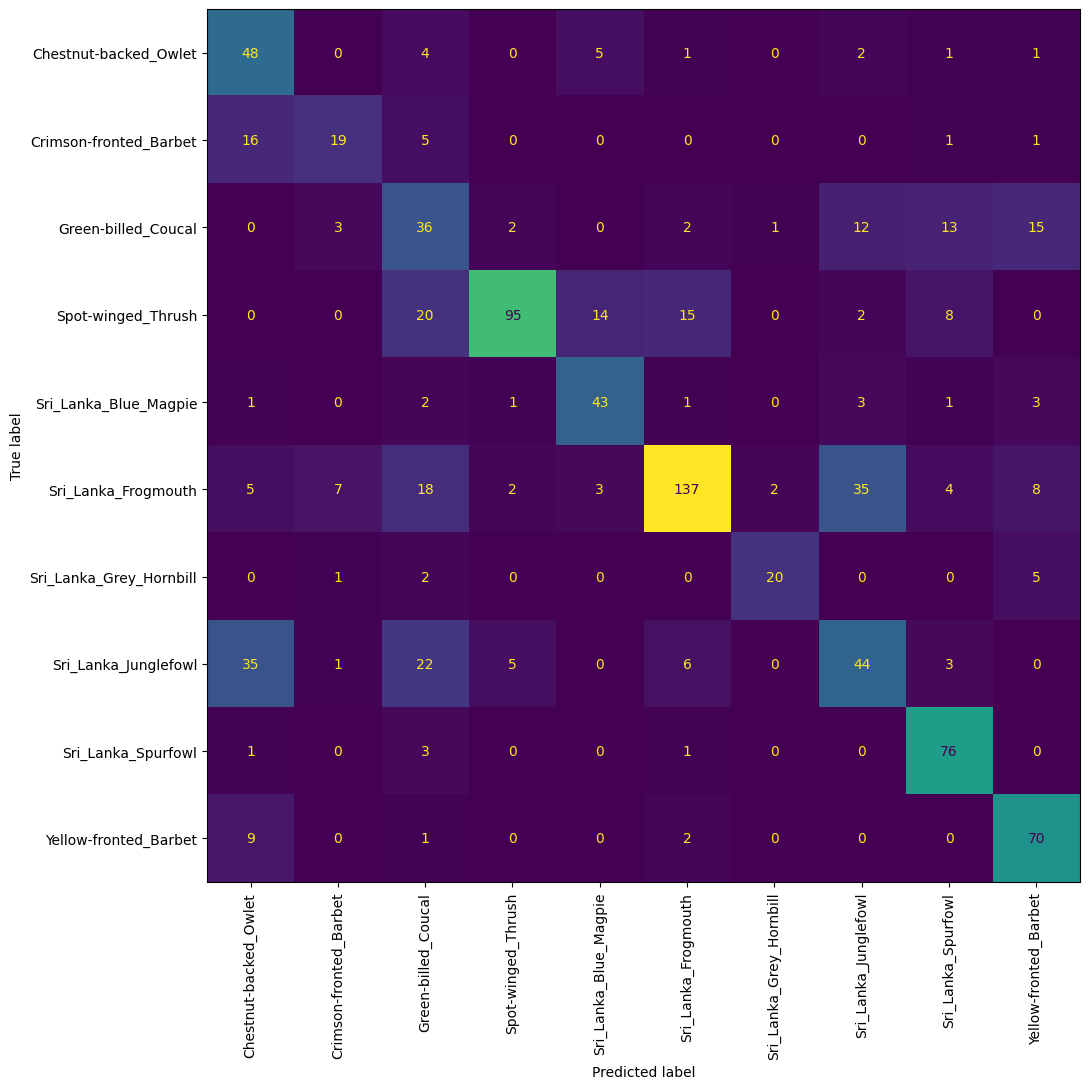

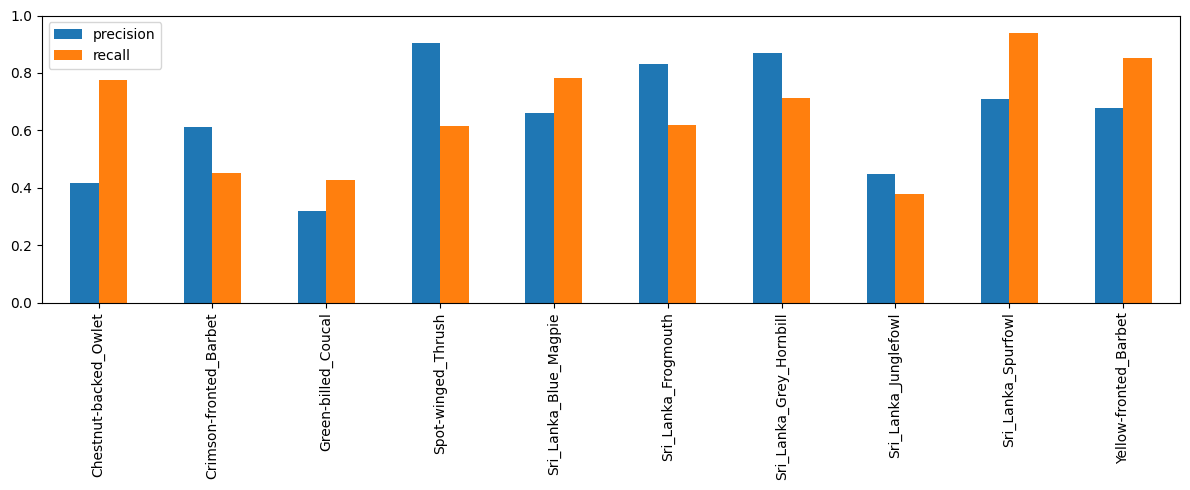

,precision,recall,f1-score,support
Chestnut-backed_Owlet,0.417391,0.774194,0.542373,62.0
Crimson-fronted_Barbet,0.612903,0.452381,0.520548,42.0
Green-billed_Coucal,0.318584,0.428571,0.365482,84.0
Spot-winged_Thrush,0.904762,0.616883,0.733591,154.0
Sri_Lanka_Blue_Magpie,0.661538,0.781818,0.716667,55.0
Sri_Lanka_Frogmouth,0.830303,0.619910,0.709845,221.0
Sri_Lanka_Grey_Hornbill,0.869565,0.714286,0.784314,28.0
Sri_Lanka_Junglefowl,0.448980,0.379310,0.411215,116.0
Sri_Lanka_Spurfowl,0.710280,0.938272,0.808511,81.0
Yellow-fronted_Barbet,0.679612,0.853659,0.756757,82.0


{'macro_f1': 0.6349301093722696, 'accuracy': 0.6356756756756756, 'loss': 1.3956934337684117}


In [10]:
required_setup = ('RUN_DIR', 'ROOT', 'frames', 'train_df', 'val_df', 'SEED', 'MODEL_REVISION', 'PACKAGE_ZIP_SHA256', 'id2label', 'fit', 'evaluate', 'save_json', 'sha256', 'cleanup')
missing_setup = [name for name in required_setup if name not in globals()]
if missing_setup:
    raise RuntimeError('Section 9 needs the setup cells from sections 1 through 7 in this kernel. Run those cells from the top, skip completed tuning in section 8, then rerun section 9. Missing: ' + ', '.join(missing_setup))

def save_evaluation(model, frame, weights, hp, directory, name):
    result, truth, predicted = evaluate(model, frame, weights, hp['batch_size'])
    names = [id2label[i] for i in range(10)]
    report = classification_report(truth, predicted, labels=list(range(10)),
                                   target_names=names, output_dict=True, zero_division=0)
    save_json(directory/f'{name}_metrics.json', result)
    save_json(directory/f'{name}_classification_report.json', report)
    per_species = pd.DataFrame(report).T.loc[names]
    per_species.to_csv(directory/f'{name}_per_species.csv', index_label='species')
    predictions = frame[['audio_path','species','label','parent_recording_id','final_group_id']].copy()
    predictions['predicted_label'] = predicted
    predictions.to_csv(directory/f'{name}_predictions.csv', index=False)
    matrix = confusion_matrix(truth, predicted, labels=list(range(10)))
    pd.DataFrame(matrix,index=names,columns=names).to_csv(directory/f'{name}_confusion_matrix.csv')
    fig, ax = plt.subplots(figsize=(12,11))
    ConfusionMatrixDisplay(matrix,display_labels=names).plot(ax=ax,xticks_rotation=90,colorbar=False)
    fig.tight_layout();fig.savefig(directory/f'{name}_confusion_matrix.png',dpi=150);plt.show();plt.close(fig)
    fig, ax = plt.subplots(figsize=(12,5))
    per_species[['precision','recall']].plot.bar(ax=ax,ylim=(0,1))
    fig.tight_layout();fig.savefig(directory/f'{name}_precision_recall.png',dpi=150);plt.show();plt.close(fig)
    display(per_species);print(result)
    return result

RUN_FINAL_TRAINING=True  # Enable section 9 in a kernel that still has the earlier settings.
FINAL_DIR = RUN_DIR/'final'
if RUN_FINAL_TRAINING:
    assert (RUN_DIR/'selected_hyperparameters.json').is_file(), 'Complete tuning first.'
    BEST_HP = json.loads((RUN_DIR/'selected_hyperparameters.json').read_text())['hyperparameters']
    final_model = None
    try:
        final_model, final_weights, final_result = fit(train_df,val_df,BEST_HP,FINAL_DIR,SEED)
        validation_metrics = save_evaluation(final_model,val_df,final_weights,BEST_HP,FINAL_DIR,'validation')
        save_json(FINAL_DIR/'selection_finalized.json', {
            'hyperparameters':BEST_HP,'seed':SEED,'best_epoch':final_result['best_epoch'],
            'checkpoint_revision':MODEL_REVISION,'package_zip_sha256':PACKAGE_ZIP_SHA256,
            'manifest_sha256':{s:sha256(ROOT/f'{s}.csv') for s in frames},
            'test_used_for_selection':False})
    except RuntimeError as exc:
        if 'out of memory' in str(exc).lower():
            raise RuntimeError('Final training ran out of GPU memory. Do not run test. Start a new run with feasible batch choices.') from exc
        raise
    finally:
        if final_model is not None: final_model.cpu();del final_model
        cleanup()
else:
    print('Final training disabled. Enable RUN_FINAL_TRAINING after tuning.')


## 10. Explicit final test evaluation - run once after model selection
Do not enable this cell until the configuration and validation-selected checkpoint are final. Test results must not guide subsequent hyperparameter choices. This cell refuses to overwrite an existing test evaluation. It loads the frozen checkpoint rather than retraining. Validation and test stay clean; this does not measure independent-noise robustness.


In [11]:
RUN_FINAL_TEST = False  # Explicitly change only after model selection is finalized.
if RUN_FINAL_TEST:
    assert (FINAL_DIR/'selection_finalized.json').is_file(), 'Finalize training/validation first.'
    assert not (FINAL_DIR/'test_metrics.json').exists(), 'Test already evaluated; inspect saved results.'
    frozen = json.loads((FINAL_DIR/'selection_finalized.json').read_text())
    hp = frozen['hyperparameters']
    weights = torch.tensor(json.loads((FINAL_DIR/'class_weights.json').read_text())['weights'],dtype=torch.float32)
    test_model = ModelClass.from_pretrained(FINAL_DIR/'best_model',attn_implementation='eager').to(DEVICE)
    try:
        test_metrics = save_evaluation(test_model,test_metadata,weights,hp,FINAL_DIR,'test')
    finally:
        test_model.cpu();del test_model;cleanup()
else:
    print('Test remains locked. No test predictions or metrics computed.')


Test remains locked. No test predictions or metrics computed.


## 11. Local file inference
After training, optionally set `INFERENCE_FILES` to one or more local audio paths. Each file is decoded to mono 16 kHz, divided into five-second segments, and the final short segment is zero-padded. Scores are uncalibrated closed-set confidence.


In [12]:
RUN_UPLOAD_INFERENCE = False
INFERENCE_FILES = []  # Example: [Path('path/to/bird_recording.wav')]
if RUN_UPLOAD_INFERENCE:
    import librosa
    assert (FINAL_DIR/'selection_finalized.json').is_file(), 'Train a model first.'
    inference_extractor = AutoFeatureExtractor.from_pretrained(FINAL_DIR/'best_model')
    inference_model = ModelClass.from_pretrained(FINAL_DIR/'best_model',attn_implementation='eager').to(DEVICE).eval()
    try:
        assert INFERENCE_FILES, 'Set INFERENCE_FILES to local audio paths first.'
        for input_path in map(Path, INFERENCE_FILES):
            assert input_path.is_file(), f'File not found: {input_path}'
            filename = str(input_path)
            audio, sr = librosa.load(input_path,sr=16000,mono=True)
            if not len(audio) or not np.isfinite(audio).all() or not np.any(audio):
                print(filename, 'empty, invalid or digitally silent; no prediction');continue
            scores=[];durations=[];segments=[]
            for start in range(0,len(audio),80000):
                segment = audio[start:start+80000]; actual = len(segment)
                if not np.any(segment): continue
                segment = np.pad(segment,(0,80000-actual))
                kwargs = {'padding':True,'return_attention_mask':base_config.feat_extract_norm=='layer'}
                inputs = inference_extractor([segment],sampling_rate=16000,return_tensors='pt',**kwargs)
                inputs = {key:value.to(DEVICE) for key,value in inputs.items()}
                with torch.inference_mode(), autocast_context():
                    probabilities = inference_model(**inputs).logits.float().softmax(-1)[0].cpu().numpy()
                scores.append(probabilities);durations.append(actual)
                label = int(probabilities.argmax())
                segments.append({'start_seconds':start/16000,'content_seconds':actual/16000,
                                 'species':id2label[label],'confidence':float(probabilities[label])})
            combined = np.average(scores,axis=0,weights=durations)
            print(filename);display(pd.DataFrame(segments))
            display(pd.DataFrame({'species':[id2label[i] for i in range(10)],'confidence':combined}).sort_values('confidence',ascending=False))
    finally:
        inference_model.cpu();del inference_model;cleanup()


## Interpretation and references
This notebook has been checked for structure and syntax but has not completed a local model training run. No accuracy or F1 results are claimed. Quality/provenance flags remain in the manifests; energy is not a bird-presence annotation. Recording-group separation respects known and precautionary groups, but unknown original-event provenance remains unresolved. Six single-source noise categories do not establish independent-noise generalization. Original clean validation/test sets are used as supplied.

API references: [Wav2Vec2](https://huggingface.co/docs/transformers/v4.57.1/model_doc/wav2vec2), [AST](https://huggingface.co/docs/transformers/v4.57.1/model_doc/audio-spectrogram-transformer), [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html), [Optuna reproducibility](https://optuna.readthedocs.io/en/stable/faq.html).
